In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, f1_score, confusion_matrix, classification_report, recall_score

In [ ]:
class Classifier:

    def prepare_data(self, dataset):
        X = dataset.data
        y = dataset.target


        self.dataset = dataset
        self.X_train, self.X_test, self.y_train, self.y_test = train_test_split(X, y, test_size=0.20)

    def predict(self, classifier):

        classifier.fit(self.X_train, self.y_train)
        y_pred = classifier.predict(self.X_test)

        print(f"\n{'-' * 50}")
        print(f"Classifier: {type(classifier).__name__}")
        print(f"{'-' * 50}\n")

        print("Confusion Matrix:")
        print(confusion_matrix(self.y_test, y_pred))

        print("\n--------\n")

        print("Performance Evaluation:")
        print(classification_report(self.y_test, y_pred, zero_division=0))

        if(isinstance(classifier, DecisionTreeClassifier)):
          print(f"\n{'-' * 50}")
          print("Text Representation")
          print(f"{'-' * 50}\n")
          text_representation = tree.export_text(classifier)
          print(text_representation)

          fig = plt.figure(figsize=(25,20))
          _ = tree.plot_tree(decision_tree=classifier, feature_names=self.dataset.feature_names, filled = True)
          fig.savefig("./decision_tree.png")

    def classify(self, dataset, dataset_name, parameters):
        print(f"\n{'=' * 50}")
        print(f"Dataset: {dataset_name}")
        print(f"{'=' * 50}")

        self.prepare_data(dataset)

        self.predict(MultinomialNB(**parameters["multinomialNB"]))
        self.predict(GaussianNB(**parameters["gaussianNB"]))
        self.predict(BernoulliNB(**parameters["bernoulliNB"]))
        self.predict(DecisionTreeClassifier(**parameters["decisionTreeGini"]))
        self.predict(DecisionTreeClassifier(**parameters["decisionTreeEntropy"]))

In [ ]:
iris = load_iris()
breast_cancer = load_breast_cancer()

classifier = Classifier()


Dataset: Iris Dataset

--------------------------------------------------
Classifier: MultinomialNB
--------------------------------------------------

Confusion Matrix:
[[ 6  0  0]
 [ 0 10  0]
 [ 0  6  8]]

--------

Performance Evaluation:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         6
           1       0.62      1.00      0.77        10
           2       1.00      0.57      0.73        14

    accuracy                           0.80        30
   macro avg       0.88      0.86      0.83        30
weighted avg       0.88      0.80      0.80        30


--------------------------------------------------
Classifier: GaussianNB
--------------------------------------------------

Confusion Matrix:
[[ 6  0  0]
 [ 0  9  1]
 [ 0  1 13]]

--------

Performance Evaluation:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         6
           1       0.90      0.90      0.90       

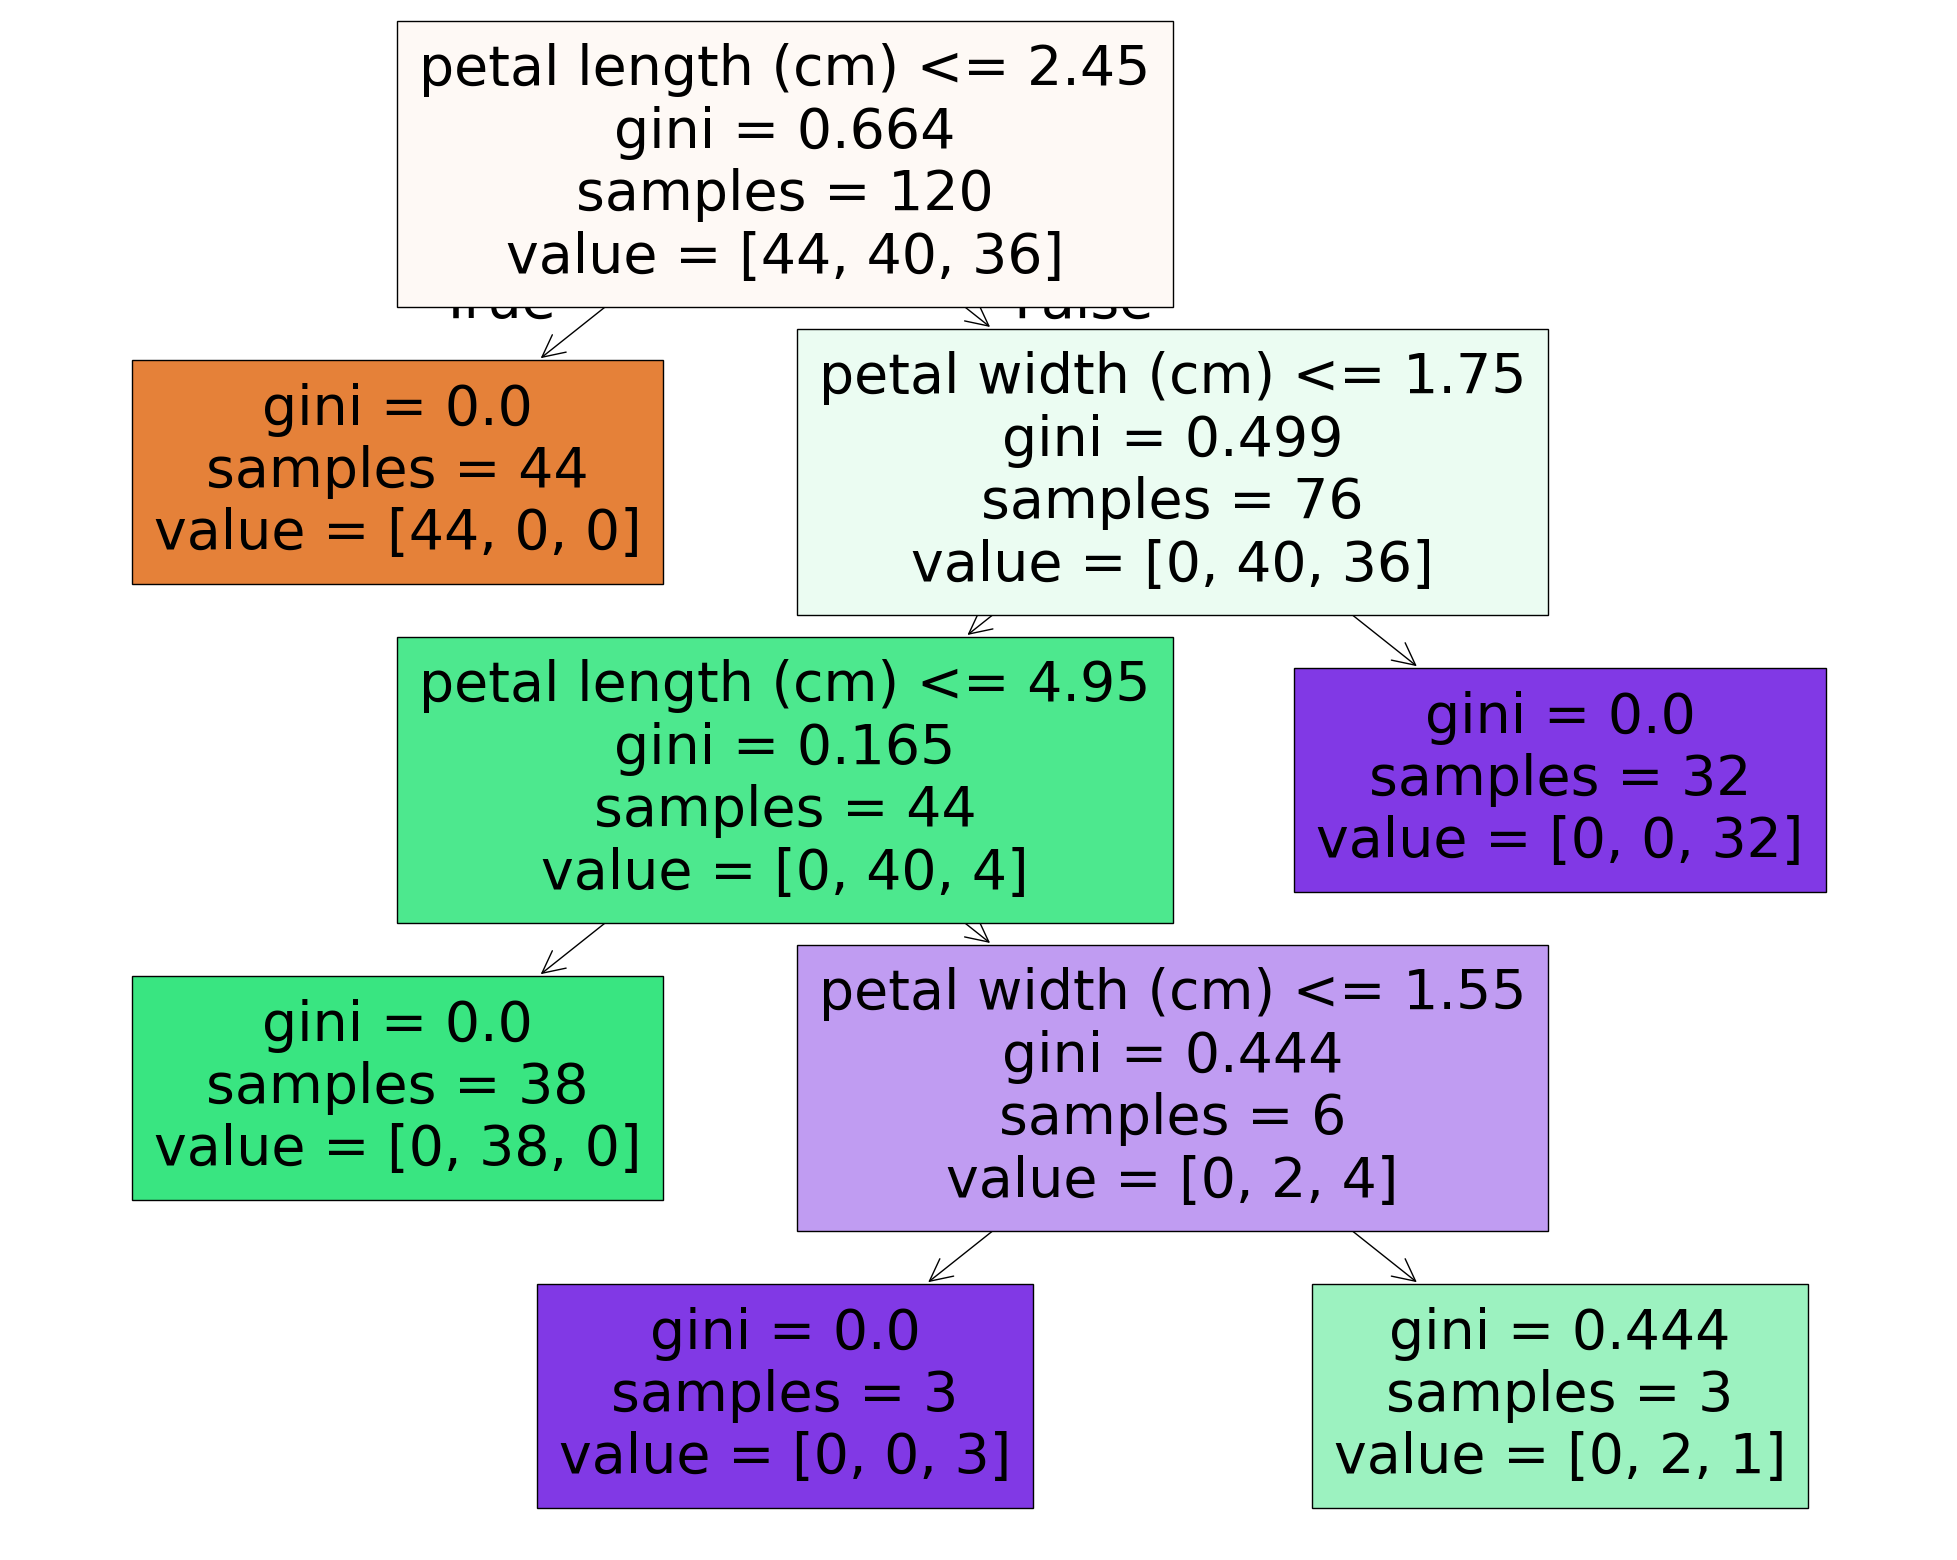

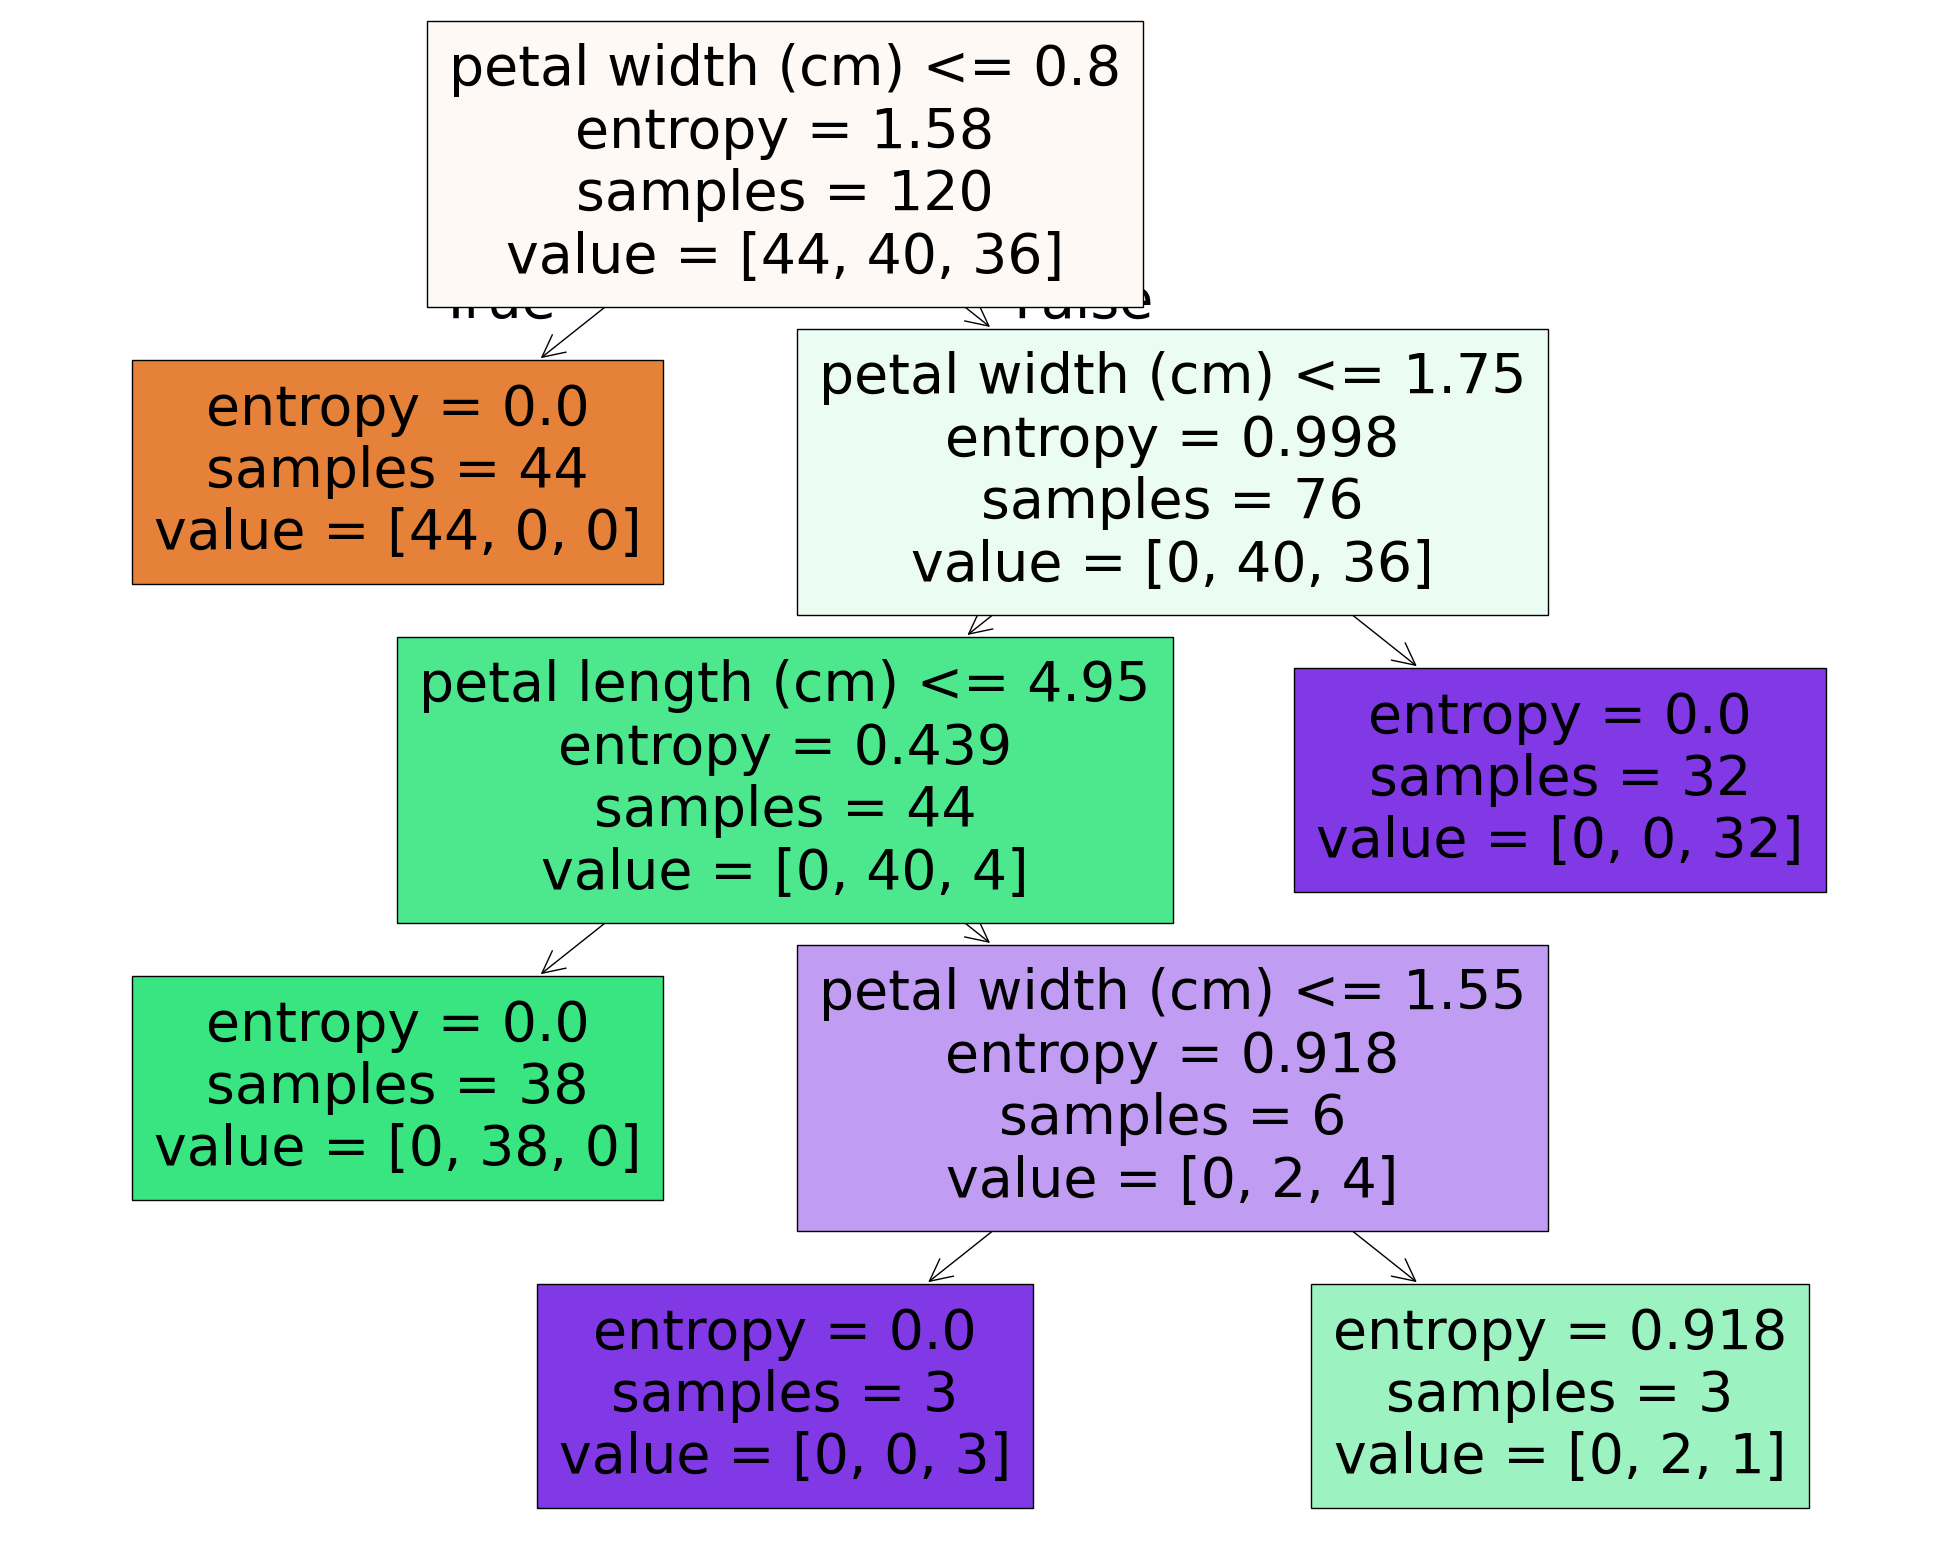

In [ ]:
iris_params = {
    "multinomialNB": {
        "alpha": 1.75
    },
    "gaussianNB": {
        "var_smoothing": 1e-9
    },
    "bernoulliNB": {
        "alpha": 0.25,
        "fit_prior": False,
        "binarize": 1.75
    },
    "decisionTreeGini": {
        "criterion": "gini",
        "max_depth": 10,
        "min_samples_split": 5
    },
    "decisionTreeEntropy": {
        "criterion": "entropy",
        "max_depth": 10,
        "min_samples_split": 5
    }
}
classifier.classify(iris, "Iris Dataset", iris_params)


Dataset: Breast Cancer Dataset

--------------------------------------------------
Classifier: MultinomialNB
--------------------------------------------------

Confusion Matrix:
[[40  5]
 [ 0 69]]

--------

Performance Evaluation:
              precision    recall  f1-score   support

           0       1.00      0.89      0.94        45
           1       0.93      1.00      0.97        69

    accuracy                           0.96       114
   macro avg       0.97      0.94      0.95       114
weighted avg       0.96      0.96      0.96       114


--------------------------------------------------
Classifier: GaussianNB
--------------------------------------------------

Confusion Matrix:
[[41  4]
 [ 0 69]]

--------

Performance Evaluation:
              precision    recall  f1-score   support

           0       1.00      0.91      0.95        45
           1       0.95      1.00      0.97        69

    accuracy                           0.96       114
   macro avg       0.9

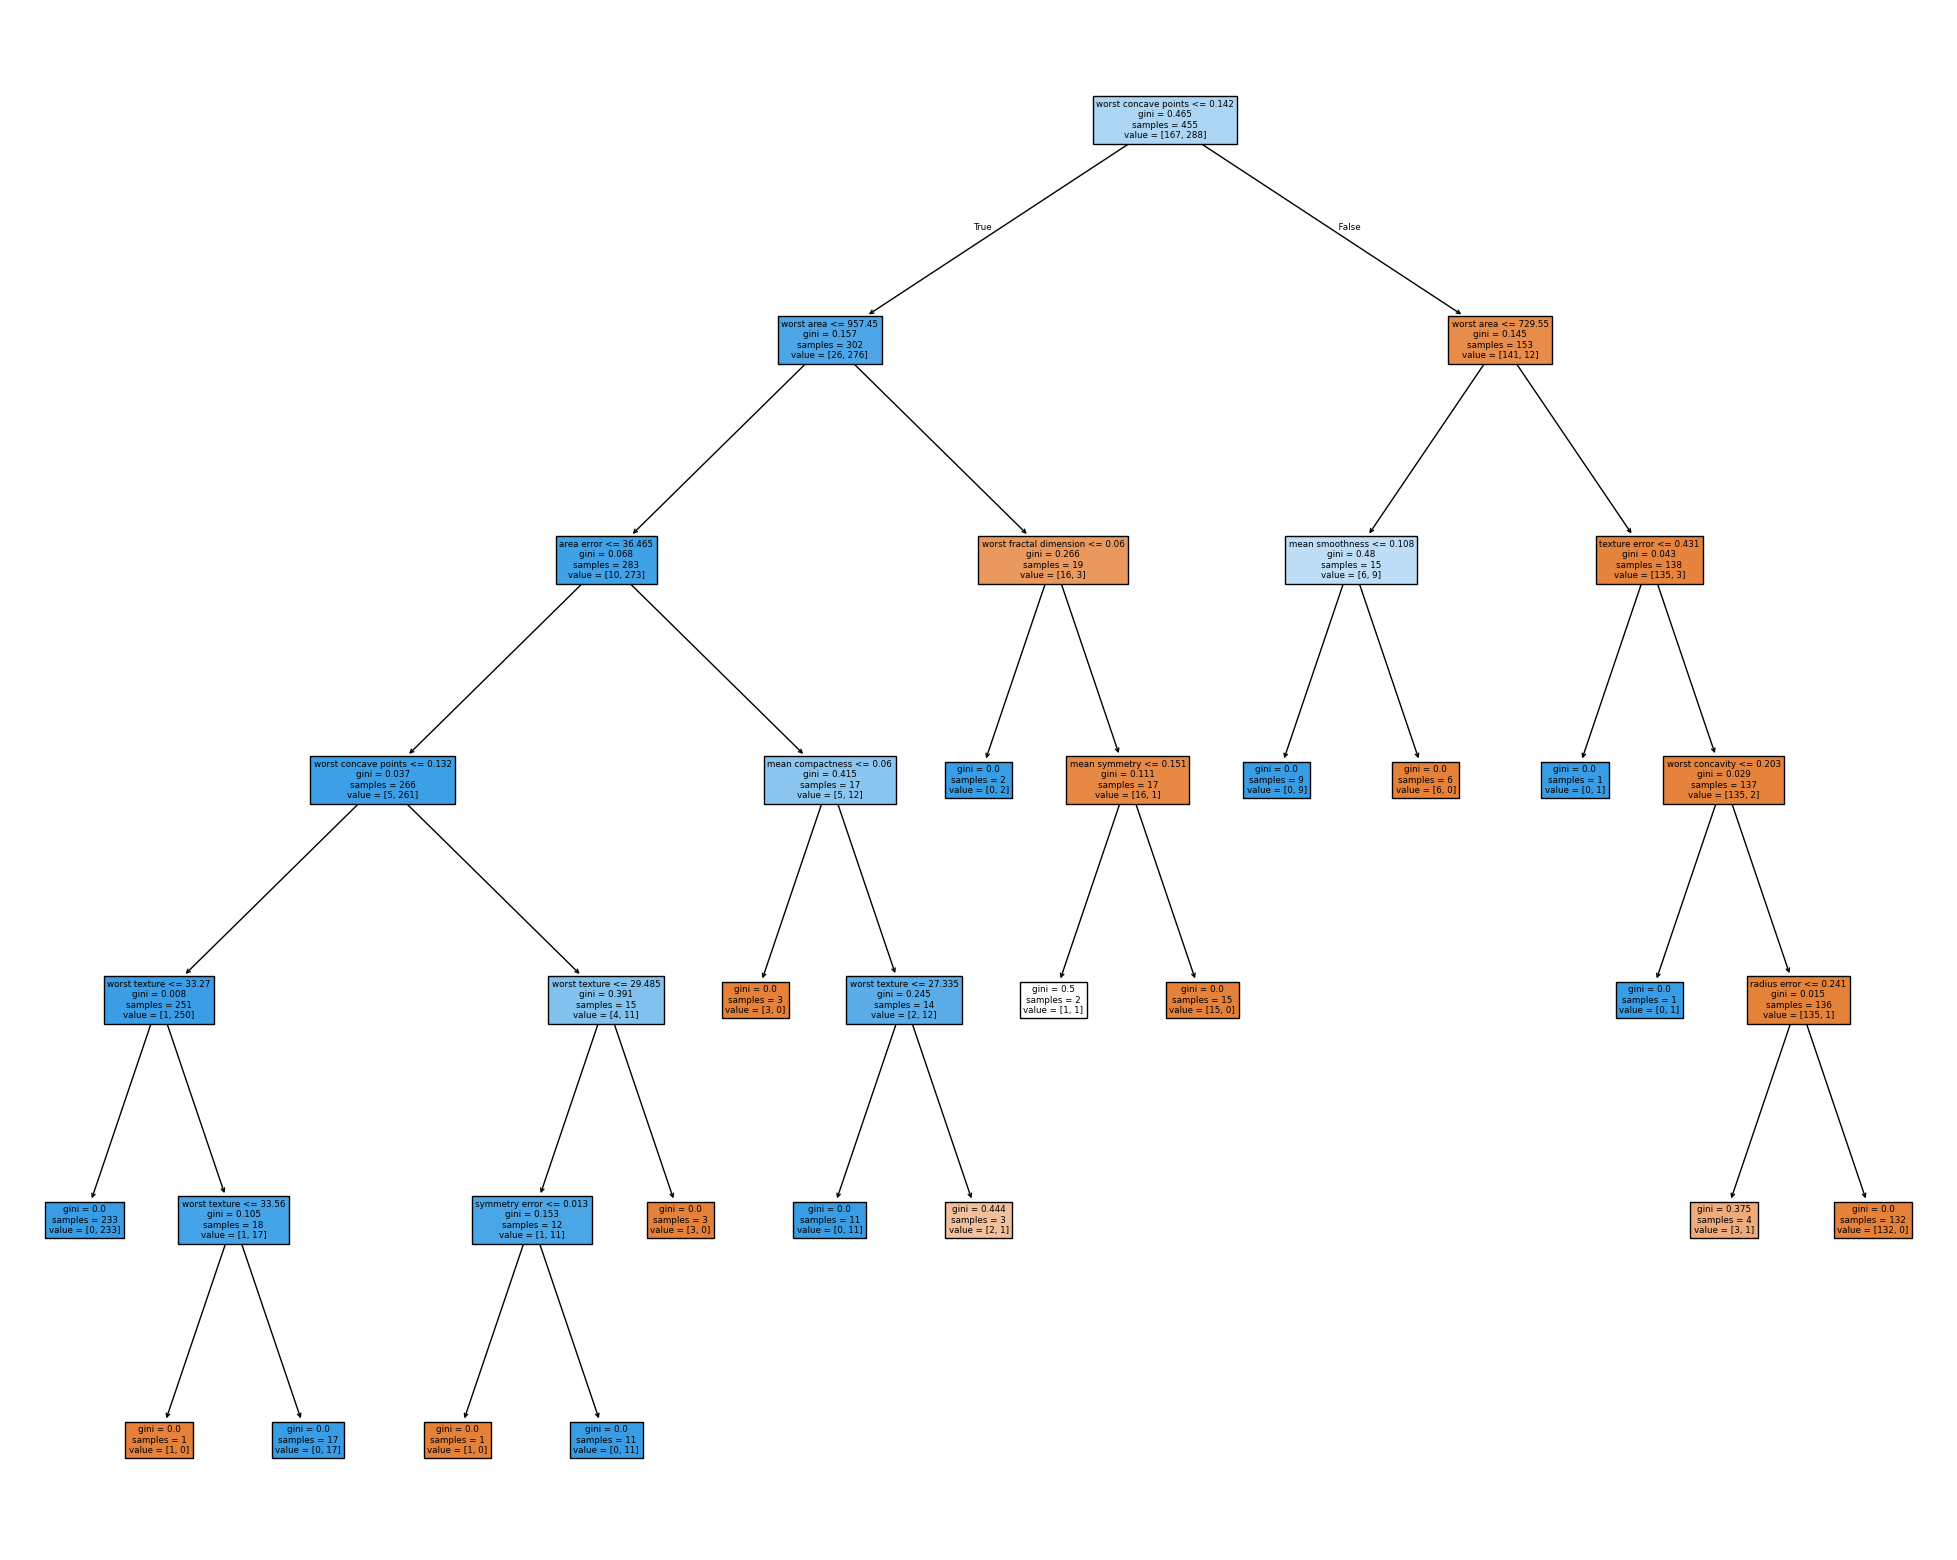

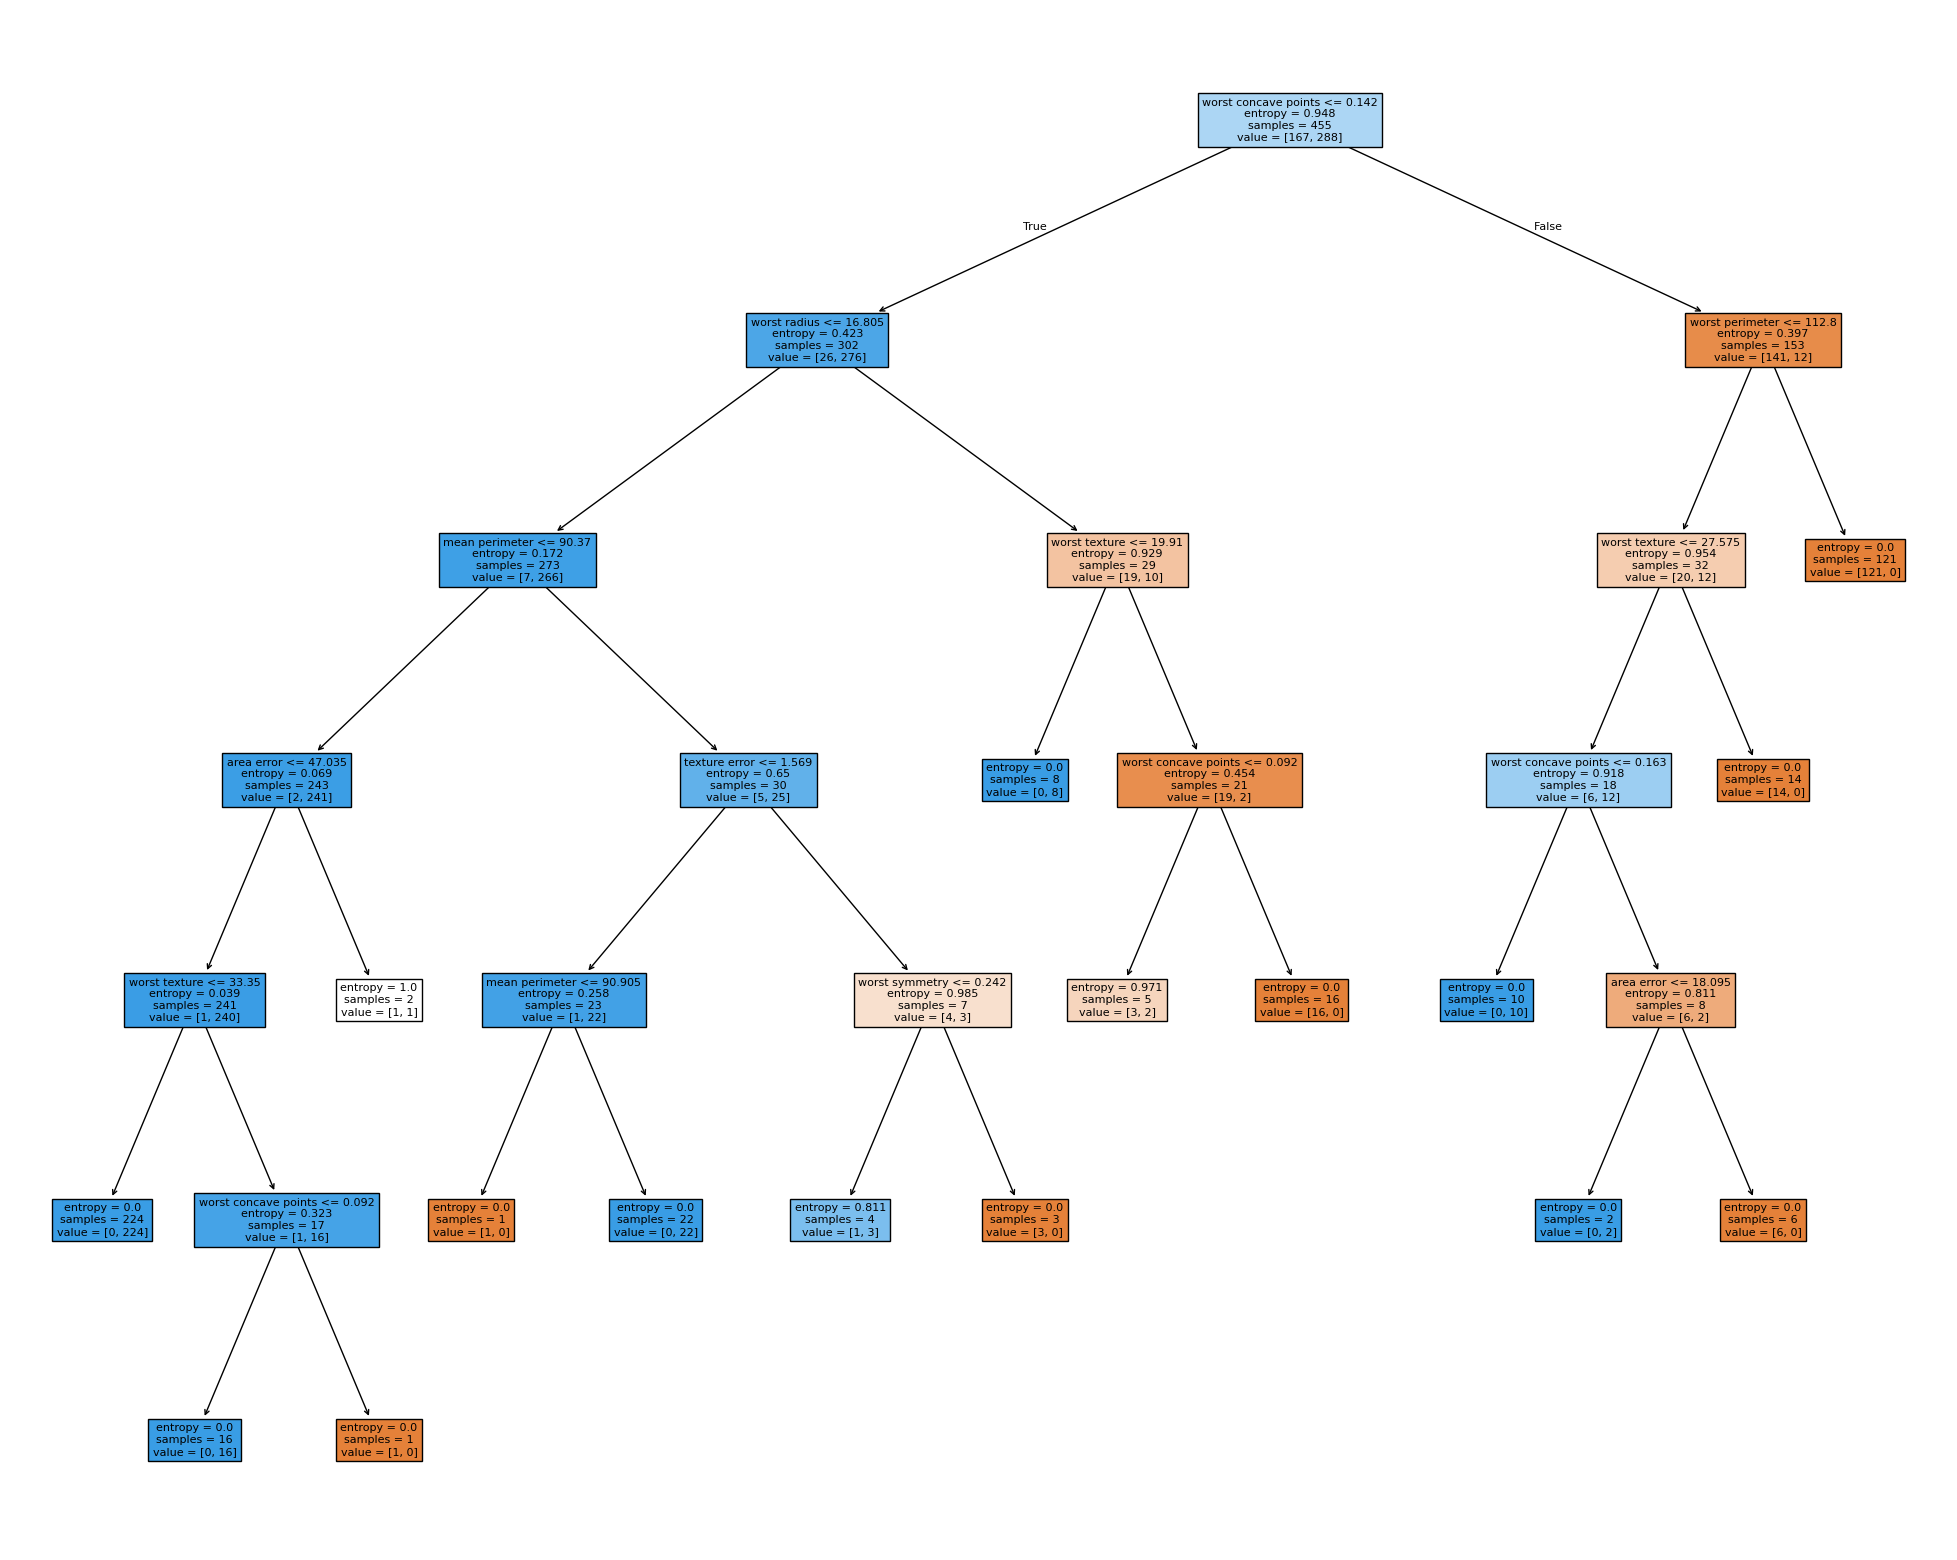

In [ ]:
breast_cancer_params = {
    "multinomialNB": {
        "alpha": 0.75
    },
    "gaussianNB": {
        "var_smoothing": 1e-9
    },
    "bernoulliNB": {
        "alpha": 0.25,
        "fit_prior": False,
        "binarize": 0.05
    },
    "decisionTreeGini": {
        "criterion": "gini",
        "max_depth": 10,
        "min_samples_split": 7
    },
    "decisionTreeEntropy": {
        "criterion": "entropy",
        "max_depth": 10,
        "min_samples_split": 7
    }
}
classifier.classify(breast_cancer, "Breast Cancer Dataset", breast_cancer_params)